<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="40"/>&nbsp;&nbsp;&nbsp;&nbsp;<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/c3s_logoline_pos.png" alt="Copernicus" height="28"/>

# Senegal's 2024 rainy season in ERA5 🌧️
### Copernicus Climate Change Service · ERA5 · free account
*Made for SEWA, Strengthening Early Warnings for Africa*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5.ipynb)

How wet was the 2024 rainy season (June to October) compared with a normal year? This notebook uses the
**ERA5 monthly means**, the Copernicus reanalysis that ECMWF produces for the European Union, to compare 2024 with
the 1991–2020 average, as a percentage of normal. The Senegal River rises in the highlands of Guinea and Mali, so the
map covers its whole basin.

**What you need:** a Google account (to use Colab) and a free Copernicus account (step below). Everything runs on Google's computers: the data is downloaded there, not to your phone
or laptop, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| ERA5 monthly means, about 31 km | Total precipitation, June–October, 1991–2024 | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the season, the year and the area

In [4]:
AREA   = [18.0, -18.5, 9.0, -6.0]                     # north, west, south, east
YEAR   = 2024
MONTHS = ["06", "07", "08", "09", "10"]               # June to October
DAYS   = {"06": 30, "07": 31, "08": 31, "09": 30, "10": 31}
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5 monthly rainfall, 1991–2020 and the chosen year

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-single-levels-monthly-means", {
    "product_type": "monthly_averaged_reanalysis", "variable": "total_precipitation",
    "year": [str(y) for y in range(1991, 2021)] + [str(YEAR)], "month": MONTHS, "time": "00:00",
    "area": AREA, "data_format": "grib"}).to_xarray()
tp = era[list(era.data_vars)[0]]                                   # metres per day, monthly mean
tdim = [d for d in tp.dims if d not in ("latitude", "longitude")][0]
t = tp[tdim].dt
mm = tp * 1000 * tp[tdim].dt.days_in_month                       # -> mm in each month
season = mm.groupby(t.year).sum(tdim)                             # mm over June-October, each year
normal = season.sel(year=slice(1991, 2020)).mean("year")
this = season.sel(year=YEAR)
pct = 100 * this / normal
print(f"{YEAR}: {float(this.mean()):.0f} mm across the box, normal {float(normal.mean()):.0f} mm "
      f"({float(100 * this.mean() / normal.mean()):.0f}% of normal)")
for n, la, lo in CITIES:
    print(f"  {n:12s} {float(this.sel(latitude=la, longitude=lo, method='nearest')):5.0f} mm, "
          f"{float(pct.sel(latitude=la, longitude=lo, method='nearest')):4.0f}% of normal")

2024: 916 mm across the box, normal 752 mm (122% of normal)
  Dakar          480 mm,  175% of normal
  Saint-Louis    101 mm,   70% of normal
  Touba          388 mm,  103% of normal
  Tambacounda    634 mm,  109% of normal
  Ziguinchor    1445 mm,  122% of normal
  Kédougou       849 mm,  104% of normal


## 3 · Map it

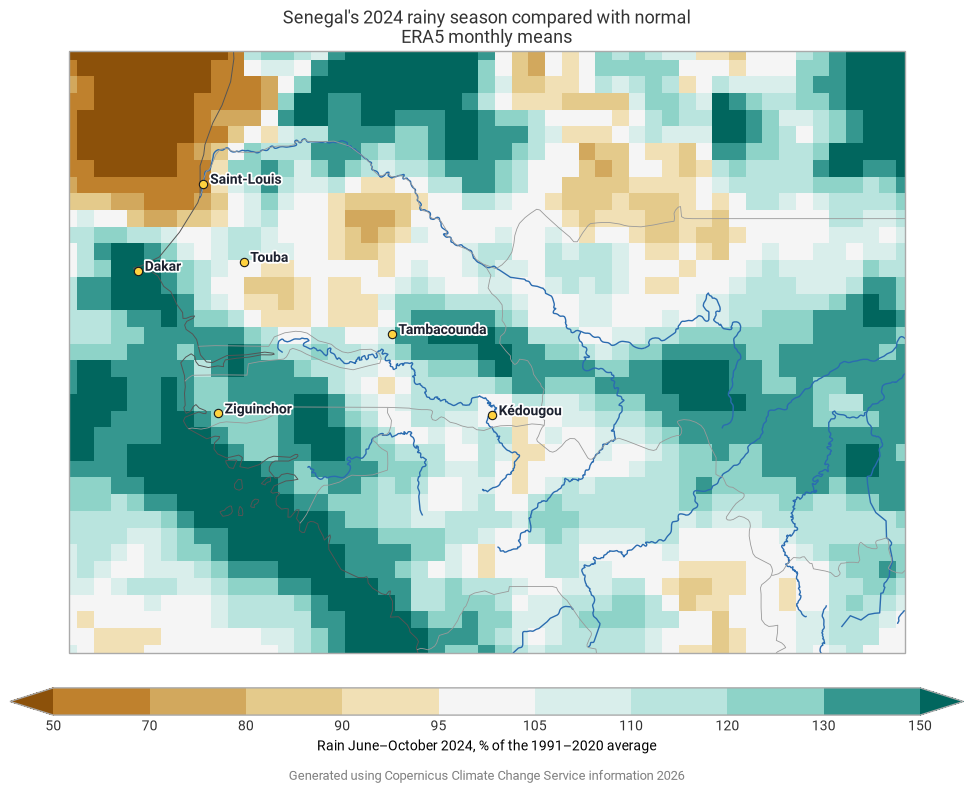

In [6]:
colors = ["#8c510a", "#bf812d", "#dfc27d", "#f6e8c3", "#f5f5f5", "#c7eae5", "#80cdc1", "#35978f", "#01665e"]
style = ekp.styles.Style(levels=[50, 70, 80, 90, 95, 105, 110, 120, 130, 150], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 7.5))
chart.pcolormesh(pct, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
chart.ax.add_feature(__import__("cartopy").feature.RIVERS, edgecolor="#2b6cb0", linewidth=1.0)
label_cities(chart.ax)
chart.legend(label=f"Rain June–October {YEAR}, % of the 1991–2020 average")
chart.title(f"Senegal's {YEAR} rainy season compared with normal\nERA5 monthly means", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("rain_era5.png")
chart.show()

## 4 · Your turn 🌍

- **Another year:** `YEAR = 2020` or any year from 1940.
- **Just the peak months:** `MONTHS = ["08", "09"]`.
- **Hotter or cooler than normal:** `"2m_temperature"` (kelvin) and `this - normal` instead of a percentage.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)